# Punto 4: Competencia y oportunidades (EcoFood)

**Qué busco:** dentro de la base de locales gastronómicos ver cuánta oferta **saludable** hay, de qué tipo es,
en qué barrios está y qué falta.

**Base que uso:** `data/processed/establecimientos_clean.csv`, que sale de la limpieza del punto 1
(`notebooks/01_limpieza_oferta.ipynb`). Ya viene sin duplicados, con los nulos resueltos y con dos columnas
que marcan si un local es saludable.

### Paso 1: cargar la base limpia

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/establecimientos_clean.csv")
print("Locales en la base:", len(df))

Locales en la base: 2811


### Paso 2: ¿qué tipos de cocina hay en el mercado?
Cuento cuántos locales hay de cada tipo de cocina con `value_counts()`. Así veo qué está **sobrerrepresentado**.
`SIN DATO` son los locales que no tienen cargado el tipo de cocina.

In [2]:
df["cocina"].value_counts().head(10)

cocina
MINUTAS          735
INTERNACIONAL    446
SIN DATO         356
TRADICIONAL      296
PIZZERIA         175
PARRILLA         158
SANDWICHERIA     127
FAST FOOD         80
ITALIANA          77
MEDITERRANEA      48
Name: count, dtype: int64

**Lectura:** minutas, internacional, tradicional y pizzería dominan el mercado. Lo saludable ni aparece en el top 10.

### Paso 3: los dos criterios de "saludable"
La base no trae una columna "saludable" original, así que en la limpieza se armaron dos, a partir de `cocina`:

- **Estricto** (`es_saludable_estricto`): NATURISTA y VEGETARIANA. Son los claramente saludables.
- **Amplio** (`es_saludable_amplio`): el estricto + MEDITERRANEA, SUSHI y JAPONESA, que se suelen asociar
  a comida más liviana.

Uso los dos: el **estricto** para ver qué tipo de locales son, y el **amplio** para el análisis por barrio
(con 11 locales solamente casi todos los barrios darían 0, y no se podría comparar).

In [3]:
estrictos = df[df["es_saludable_estricto"]]
amplios = df[df["es_saludable_amplio"]]

print("Saludables (estricto):", len(estrictos), "=", round(len(estrictos) / len(df) * 100, 1), "% del mercado")
print("Saludables (amplio):  ", len(amplios), "=", round(len(amplios) / len(df) * 100, 1), "% del mercado")

Saludables (estricto): 11 = 0.4 % del mercado
Saludables (amplio):   80 = 2.8 % del mercado


In [4]:
estrictos[["nombre", "categoria", "cocina", "barrio"]]

,nombre,categoria,cocina,barrio
65,ALMACEN NATURISTA,RESTAURANTE,NATURISTA,Recoleta
299,BIO,RESTAURANTE,VEGETARIANA,Palermo
691,DEMETRIA,RESTAURANTE,NATURISTA,Saavedra
1160,GRANIX RESTAURANT,RESTAURANTE,VEGETARIANA,San Nicolás
1297,KRISHNA,RESTAURANTE,VEGETARIANA,Palermo
1366,LA CASA DE OSHAUA,RESTAURANTE,NATURISTA,Colegiales
1425,LA ESQUINA DE LAS FLORES,RESTAURANTE,NATURISTA,Caballito
1745,LOTOS,CAFE,NATURISTA,Recoleta
1803,MANJARES NATURALES,RESTAURANTE,NATURISTA,Floresta
2064,ORGANIC`S,RESTAURANTE,NATURISTA,Palermo


In [5]:
amplios["cocina"].value_counts()

cocina
MEDITERRANEA    48
SUSHI           12
JAPONESA         9
NATURISTA        7
VEGETARIANA      4
Name: count, dtype: int64

**Lectura:** con el criterio estricto hay solo 11 locales (0,4 %). Con el amplio son 80 (2,8 %), y la mayoría
son mediterráneos o de sushi/japonesa, no naturistas.

### Paso 4: ¿de qué rubro son los locales saludables?
Comparo con el total del mercado para ver qué rubros no tienen opciones saludables.

In [6]:
rubros = pd.DataFrame({
    "total_mercado": df["categoria"].value_counts(),
    "estricto": estrictos["categoria"].value_counts(),
    "amplio": amplios["categoria"].value_counts(),
})
rubros = rubros.fillna(0).sort_values("total_mercado", ascending=False)
rubros

,total_mercado,estricto,amplio
categoria,,,
RESTAURANTE,1982,10.0,70.0
CAFE,332,1.0,2.0
BAR,245,0.0,2.0
SIN DATO,116,0.0,2.0
CONFITERIA,55,0.0,0.0
PUB,53,0.0,0.0
VINERIA,22,0.0,2.0
SANDWICHERIA,4,0.0,0.0
DELIVERY & TAKE AWAY,2,0.0,2.0


**Lectura:** casi todos los saludables son restaurantes. Entre los 332 cafés hay solo 1 saludable estricto
(2 con el amplio), y en confiterías y pubs no hay ninguno. Los 2 locales de take away son de sushi.

### Paso 5: ¿en qué barrios están?
Por cada barrio cuento el total de locales y los saludables con los dos criterios. Calculo el **porcentaje**
para no confundir "barrio con poca oferta saludable" con "barrio con poca gastronomía en general".

In [7]:
barrios = pd.DataFrame({
    "total_locales": df["barrio"].value_counts(),
    "estricto": estrictos["barrio"].value_counts(),
    "amplio": amplios["barrio"].value_counts(),
})
barrios = barrios.fillna(0)
barrios["porcentaje_amplio"] = round(barrios["amplio"] / barrios["total_locales"] * 100, 1)
barrios = barrios.sort_values("total_locales", ascending=False)   # de más locales a menos

barrios.head(15)

,total_locales,estricto,amplio,porcentaje_amplio
barrio,,,,
Palermo,466,3.0,33.0,7.1
San Nicolás,454,2.0,8.0,1.8
Recoleta,324,2.0,7.0,2.2
Balvanera,212,0.0,1.0,0.5
Monserrat,148,0.0,1.0,0.7
Caballito,124,1.0,4.0,3.2
Retiro,109,0.0,6.0,5.5
Flores,85,0.0,0.0,0.0
San Telmo,80,0.0,1.0,1.2


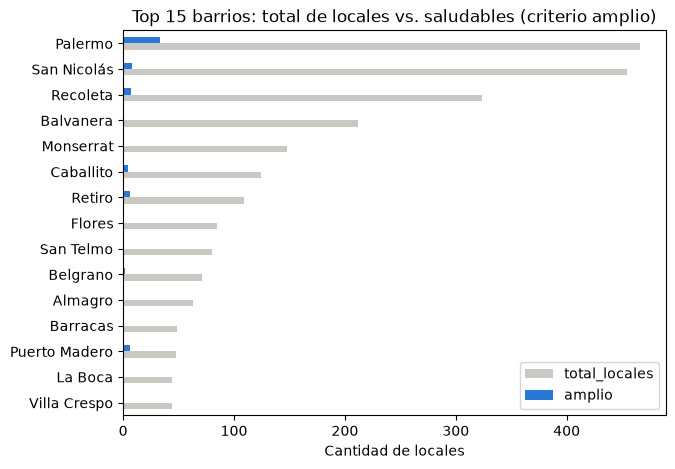

In [8]:
barrios.head(15).sort_values("total_locales").plot(kind="barh", y=["total_locales", "amplio"],
                                                   figsize=(7, 5), color=["#c9c8c2", "#2a78d6"])
plt.title("Top 15 barrios: total de locales vs. saludables (criterio amplio)")
plt.xlabel("Cantidad de locales")
plt.ylabel("")
plt.show()

**Lectura:** Palermo concentra gran parte de la oferta saludable amplia. En el resto de los barrios grandes la
barra azul casi no se ve.

### Paso 6: buscar zonas con oportunidad
Busco barrios con **mucha gastronomía** (40 locales o más, o sea que hay gente que sale a comer)
y **ningún local saludable estricto**. La columna `amplio` muestra si al menos hay algo parecido.

In [9]:
oportunidad = barrios[(barrios["total_locales"] >= 40) & (barrios["estricto"] == 0)]
oportunidad

,total_locales,estricto,amplio,porcentaje_amplio
barrio,,,,
Balvanera,212,0.0,1.0,0.5
Monserrat,148,0.0,1.0,0.7
Retiro,109,0.0,6.0,5.5
Flores,85,0.0,0.0,0.0
San Telmo,80,0.0,1.0,1.2
Belgrano,71,0.0,2.0,2.8
Almagro,63,0.0,0.0,0.0
Barracas,49,0.0,0.0,0.0
Puerto Madero,48,0.0,6.0,12.5


Los barrios donde **tampoco hay nada con el criterio amplio** son la oportunidad más clara:

In [10]:
sin_nada = oportunidad[oportunidad["amplio"] == 0]
sin_nada

,total_locales,estricto,amplio,porcentaje_amplio
barrio,,,,
Flores,85,0.0,0.0,0.0
Almagro,63,0.0,0.0,0.0
Barracas,49,0.0,0.0,0.0
La Boca,44,0.0,0.0,0.0


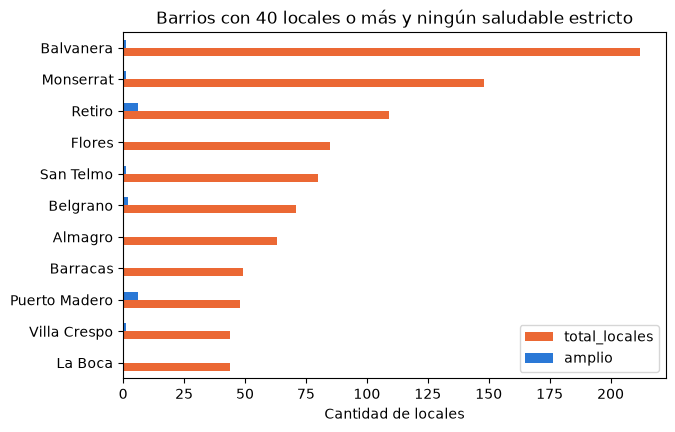

In [11]:
oportunidad.sort_values("total_locales").plot(kind="barh", y=["total_locales", "amplio"],
                                              figsize=(7, 4.5), color=["#eb6834", "#2a78d6"])
plt.title("Barrios con 40 locales o más y ningún saludable estricto")
plt.xlabel("Cantidad de locales")
plt.ylabel("")
plt.show()

## Conclusiones

1. **Casi no hay competencia directa.** Con el criterio estricto solo hay 11 locales saludables de 2.811 (0,4 %).
   Aun con el criterio amplio son 80 (2,8 %). El mercado está dominado por minutas, comida internacional,
   tradicional y pizzería.
2. **Lo que existe está concentrado en el norte y el centro.** Palermo tiene 33 de los 80 saludables amplios
   (41 %), seguido por San Nicolás y Recoleta. Además, la mayoría de esa oferta "amplia" es mediterránea o sushi,
   no una propuesta naturista o vegetariana.
3. **Zonas con oportunidad:**
   - **Más clara:** Flores, Almagro, Barracas y La Boca tienen 40 locales o más y **ninguna** opción saludable,
     con ninguno de los dos criterios.
   - **También interesantes:** Balvanera (212 locales), Monserrat (148) y San Telmo (80) tienen mucha
     gastronomía, ningún saludable estricto y apenas 1 con el criterio amplio.
4. **Formatos que faltan:** café saludable (1 de 332 cafés con el criterio estricto), take away (los 2 locales del
   rubro son de sushi) y opciones veganas o sin TACC (no aparecen en la base). Para una **línea de productos** como
   la de EcoFood, el take away y los cafés son la entrada más natural.

**Antes de darlo por bueno:**
- La base no tiene una columna "saludable" original. Las dos columnas se armaron a partir de `cocina`, y hay
  356 locales sin tipo de cocina cargado, así que los números son una aproximación.
- El criterio amplio incluye sushi y mediterránea, que no siempre son "saludables". Por eso las conclusiones
  sobre el tipo de oferta se apoyan en el estricto.
- Conviene cruzarlo con las búsquedas de Google Trends (punto 2).
